# 05 会議録の埋め込みの診断 —— BERT の埋め込みで、党の立場が見えるか

**問い**: 日本語 BERT で国会の発言をベクトルにしたとき、その主な違い(主成分)は、党の立場の違いを表しているか。表しているなら、連立再編の前後での党の動きを、そのまま測れるかもしれない。

**方法**: 前処理した会議録 88,015件の発言のベクトル(768次元。作り方は `04_embed_bert_colab.ipynb`)を主成分分析で2次元にまとめ、党ごとの平均・再編の前後・月ごとの動きを見る。さらに、第1主成分の両端の発言を読み、話し方・長さとの関係を確かめる。

**結論(先に)**: 第1主成分は、党の立場よりも**話し方のかたさと発言の長さ**を強く表していた(話し方と長さだけで第1主成分のばらつきの 43% を説明でき、党の違いで説明できるのは 8% だけ)。このため、会議録 × BERT で党の立場を測るのはやめ、立場の測定は公約と LLM による判定を主にした(種の文で向きを決める方法も `06_seed_axis_test.ipynb` で試し、同じ結論)。

**流れ**: 準備 → 1. 全発言の主成分分析 → 2. 100字以上でもう一度 → 3. 第1主成分は何を測っているか → 4. (付録)前処理の点検

※ 2026-10-25 に上から順に実行し直した。

## 準備:言葉と読み込み

- **埋め込み(ベクトル)**: 文を、768個の数の並びにしたもの。意味や言い方の似た文ほど、近い並びになる
- **主成分分析(PCA)**: たくさんの数の並びを、ばらつきが大きい順に少数の「向き」にまとめる方法。第1主成分 = 発言どうしの違いが一番大きく出る向き
- **相関係数**: 2つの値が一緒に動く度合い(−1〜1。0 なら関係なし)

ベクトルと、前処理した発言の表を読み込み、党・与党かどうか・文字数を付ける。ベクトルは 04 で作ったときの 88,297件分あるので、今の前処理の結果に残っている発言だけを使う。公明(2025-10-10 に連立離脱)と維新(2025-10-20 に連立合意)は、与党の時期と野党の時期で印を分ける。

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

plt.rcParams["font.family"] = "Yu Gothic"

# 読み込み
EMB = Path("../data/embeddings/emb")
X = np.load(EMB / "embeddings.npy")
ids = pd.read_csv(EMB / "speech_ids.csv")
q = pd.read_parquet("../data/processed/speeches.parquet",
                    columns=["speechID", "date", "party", "nameOfHouse", "nameOfMeeting", "text"])

# 新しい parquet にある発言だけ残す(除外した発言の埋め込みは使わない)
keep_ids = ids["speechID"].isin(q["speechID"]).to_numpy()
X = X[keep_ids]
ids = ids[keep_ids].reset_index(drop=True)
df = ids.merge(q, on="speechID", how="left", validate="one_to_one")

# 与党かどうか
d = df["date"]
df["gov"] = (
    (df["party"] == "自民")
    | ((df["party"] == "公明") & (d < "2025-10-10"))
    | ((df["party"] == "維新") & (d >= "2025-10-20"))
)

# 文字数
df["n_char"] = df["text"].str.len()

# 公明・維新は与党の時期と野党の時期を分ける
df["label"] = df["party"]
for p in ["公明", "維新"]:
    m = df["party"] == p
    df.loc[m, "label"] = p + df.loc[m, "gov"].map({True: "(与)", False: "(野)"})

print(X.shape, len(df), "党が空の行:", df["party"].isna().sum())
print(df["party"].value_counts().to_string())

(88015, 768) 88015 党が空の行: 0
party
立憲     23621
国民     12281
維新      9759
自民      9536
共産      7457
公明      6841
中道      5248
参政      4082
れいわ     3637
その他     2633
みらい     1465
社民       866
保守       589


**結果**: 88,015件 × 768次元。党が空の発言は無い。件数は立憲 23,621 が最多、保守 589 が最少。

与党の印が正しく付いているかを、党ごとの割合で確かめる(このセルと次のセルの最初は、上のセルと同じ計算をもう一度している。結果は変わらない)。

In [2]:
d = df["date"]
df["gov"] = (
    (df["party"] == "自民")
    | ((df["party"] == "公明") & (d < "2025-10-10"))
    | ((df["party"] == "維新") & (d >= "2025-10-20"))
)
print(df.groupby("party")["gov"].mean().round(2).sort_values())

party
その他    0.00
みらい    0.00
れいわ    0.00
中道     0.00
保守     0.00
共産     0.00
参政     0.00
国民     0.00
立憲     0.00
社民     0.00
維新     0.39
公明     0.53
自民     1.00
Name: gov, dtype: float64


**結果**: 自民 1.00、公明 0.53(離脱前の割合)、維新 0.39(合意後の割合)、ほかの党は 0 → 印は正しく付いている。

## 1. 全発言の主成分分析

ベクトルを第1・第2主成分の2次元にまとめ、党ごとの平均を点で描く。

**図の読み方**: 灰色の小さな点 = 発言1件ずつ。色の点 = 党ごとの平均(赤 = 与党、青 = 野党、かっこ内は件数)。緑の矢印 = 公明・維新の再編前 → 後。

説明できるばらつきの割合: [0.181 0.092]


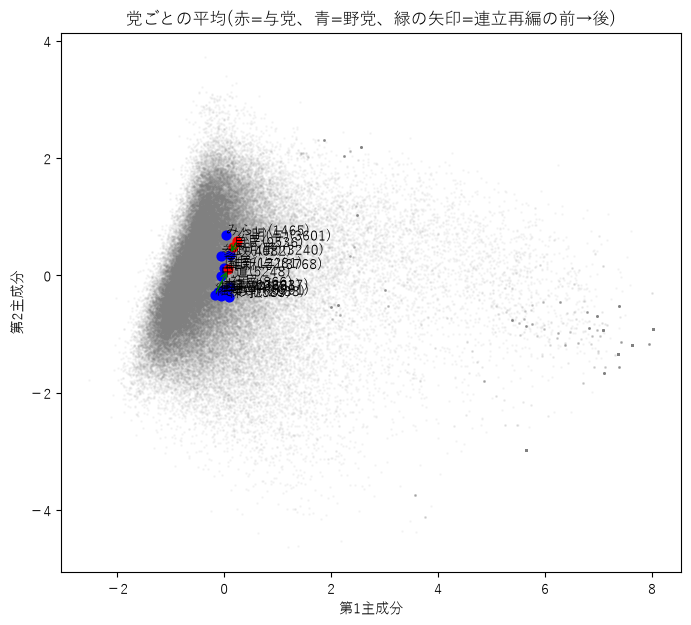

In [3]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

plt.rcParams["font.family"] = "Yu Gothic"

pca = PCA(n_components=2)
Z = pca.fit_transform(X)
df["pc1"], df["pc2"] = Z[:, 0], Z[:, 1]
print("説明できるばらつきの割合:", pca.explained_variance_ratio_.round(3))

# 公明と維新は、与党の時期と野党の時期を分けて点にする
df["label"] = df["party"]
for p in ["公明", "維新"]:
    m = df["party"] == p
    df.loc[m, "label"] = p + df.loc[m, "gov"].map({True: "(与)", False: "(野)"})

g = df.groupby("label").agg(pc1=("pc1", "mean"), pc2=("pc2", "mean"),
                            n=("pc1", "size"), gov=("gov", "mean")) 

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(df["pc1"], df["pc2"], s=1, alpha=0.05, color="gray")
for lab, r, in g.iterrows():
    color = "red" if r["gov"] > 0.5 else "blue"
    ax.scatter(r["pc1"], r["pc2"], color=color, s=40)
    ax.annotate(f"{lab}({int(r['n'])})", (r["pc1"], r["pc2"]), fontsize=10)

# 公明・維新の「前→後」を矢印で結ぶ
for p, before, after in [("公明", "(与)", "(野)"), ("維新", "(野)", "(与)")]:
    a, b = g.loc[p + before], g.loc[p + after]
    ax.annotate(
        "", 
        xy=(b["pc1"], b["pc2"]), 
        xytext=(a["pc1"], a["pc2"]), 
        arrowprops=dict(arrowstyle="->", color="green")
    ) 

ax.set_xlabel("第1主成分"); ax.set_ylabel("第2主成分")
ax.set_title("党ごとの平均(赤=与党、青=野党、緑の矢印=連立再編の前→後)")
Path("../outputs").mkdir(exist_ok=True)
plt.savefig("../outputs/pca_parties.png", dpi=150, bbox_inches="tight")
plt.show() 



**結果**: 第1主成分で全体のばらつきの 18.1%、第2主成分で 9.2% を説明できる。党ごとの平均は真ん中に固まっていて、ほとんど区別できない。一方、発言は**右(第1主成分の大きい方)へ長く伸びている**。

右端(第1主成分が 3 より大きい)の発言を読む。

In [4]:
out = df[df["pc1"] > 3]
print(len(out), "件")
print(out["party"].value_counts().to_dict())
print(
    "文字数の中央値:", 
    out["text"].str.len().median(), 
    "(全体:", 
    df["text"].str.len().median(), 
    ")"
)
for _, r in out.sample(len(out), random_state=0).iterrows():
    print(f"\n[{r['party']}・{r['nameOfMeeting']}] {r['text'][:150]}")

3521 件
{'立憲': 728, '国民': 528, '自民': 492, '維新': 479, '公明': 398, '共産': 189, '中道': 188, '参政': 145, 'れいわ': 129, 'その他': 127, 'みらい': 58, '保守': 30, '社民': 30}
文字数の中央値: 28.0 (全体: 370.0 )

[公明・地方創生及びデジタル社会の形成等に関する特別委員会] 以上で終わります。ありがとうございました。

[れいわ・内閣委員会] どうもありがとうございました。

[保守・法務委員会] それでは終わります。どうも。

[立憲・外交防衛委員会] 大変有り難いお言葉、ありがとうございます。 トップレベルで連絡を取り合ってくださるという理解でよろしいですね。

[自民・政治改革に関する特別委員会] ありがとうございます。 我が党も、一致点を見出すべく、真摯に協議をしてまいります。その思いで臨んでまいります。 以上です。ありがとうございました。

[自民・予算委員会第二分科会] ありがとうございます。 以上で質問を終わります。ありがとうございました。

[維新・厚生労働委員会] どうもありがとうございます。 本当に、本日のお話を超えて、大変大きな示唆を参考人の皆さんからいただいていると思います。今後もしっかり努めてまいりたいと思いますので、どうぞよろしくお願いします。 ありがとうございました。

[自民・財務金融委員会] 終わります。ありがとうございました。

[維新・内閣委員会] 残りはまた今度やりたいと思います。 ありがとうございました。

[国民・内閣委員会] 時間が来ましたので終わります。 ありがとうございました。

[立憲・農林水産委員会] 時間が来ましたので、終わります。ありがとうございました。

[れいわ・内閣委員会] 時間がなくなりました。 御丁寧な御回答、どうもありがとうございました。

[立憲・厚生労働委員会] 以上で終わります。ありがとうございました。

[その他・農林水産委員会] ありがとうございます。 終わります。 ◇

[国民・総務委員会] 令和八年ということで、もう来年ですので、しっかりと前に進めていただきたいと思います。 御答弁いただきまして、ありがとうございました。

[国民・予算委員会

**結果**: 右端は 3,521件で、「終わります。ありがとうございました」「大臣、いかがですか」のような**短いあいさつ・つなぎ**ばかりだった(文字数の中央値 28字。全体は 370字)。どの党にもある(立憲 728・国民 528・自民 492 など)。これが第1主成分を引っぱっている。

短い発言を除く長さを決めるため、区切りの長さごとに、除かれる件数と、そのうち右端の発言の件数を数える。

In [5]:
df["n_char"] = df["text"].str.len()

print(
    "第一主成分と文字数の相関:", 
    round(np.corrcoef(df["pc1"], np.log1p(df["n_char"]))[0, 1], 3)
)
print("右側(pc1>3)の件数:", (df["pc1"] > 3).sum())
print("右側の文字数:", df.loc[df["pc1"] > 3, "n_char"].describe(percentiles=[.5, .9, .99]).round(0).to_dict())

print("\n区切りの長さごとに、除かれる発言")
for th in [30, 50, 80, 100, 150]:
    short = df["n_char"] < th
    print(f"  {th:>3}文字未満: {short.sum():>6}件({short.mean():.1%})"
          f"  うち右側の発言 {(short & (df['pc1'] > 3)).sum()}件")

print("\n100文字未満の発言の、党ごとの割合")
print((df["n_char"] < 100).groupby(df["party"]).mean().round(3).sort_values().to_dict())

第一主成分と文字数の相関: -0.743
右側(pc1>3)の件数: 3521
右側の文字数: {'count': 3521.0, 'mean': 35.0, 'std': 23.0, 'min': 3.0, '50%': 28.0, '90%': 69.0, '99%': 102.0, 'max': 156.0}

区切りの長さごとに、除かれる発言
   30文字未満:   2565件(2.9%)  うち右側の発言 1878件
   50文字未満:   5014件(5.7%)  うち右側の発言 2696件
   80文字未満:   8662件(9.8%)  うち右側の発言 3337件
  100文字未満:  11105件(12.6%)  うち右側の発言 3482件
  150文字未満:  17092件(19.4%)  うち右側の発言 3520件

100文字未満の発言の、党ごとの割合
{'みらい': 0.057, '参政': 0.077, '公明': 0.099, '国民': 0.104, '自民': 0.104, '維新': 0.11, '中道': 0.121, 'その他': 0.135, '立憲': 0.153, '共産': 0.162, 'れいわ': 0.165, '保守': 0.182, '社民': 0.204}


**結果**
- **第1主成分と文字数(対数)の相関は −0.743**(強い関係。短い発言ほど右)
- 右端の発言は、最長でも 156字
- 100字未満を除くと、12.6%(11,105件)の発言が除かれ、右端の発言 3,521件のうち 3,482件が除かれる
- 100字未満の発言の割合は、党によって 5.7%(みらい)〜20.4%(社民)と差がある → 除くと、党によって残る件数の割合が変わる点には注意

→ **以下の分析では、100字未満を除くことにした**(`speeches.parquet` には残してあり、分析のときに除く)。

## 2. 100字以上の発言で、もう一度

100字以上の発言だけで主成分分析をやり直す。見るもの: 第1・第2主成分と、与党かどうか・長さ・日付との相関 / 党ごとの平均の図(読み方は1.と同じ)

残った発言: 76910 件
説明できるばらつきの割合: [0.134 0.074]

第一成分との相関係数
  与党かどうか: 0.186
  文字数(対数): -0.114
  日付        : 0.129

第二主成分との相関係数
  与党かどうか: 0.159
  文字数(対数): -0.17
  日付        : 0.01


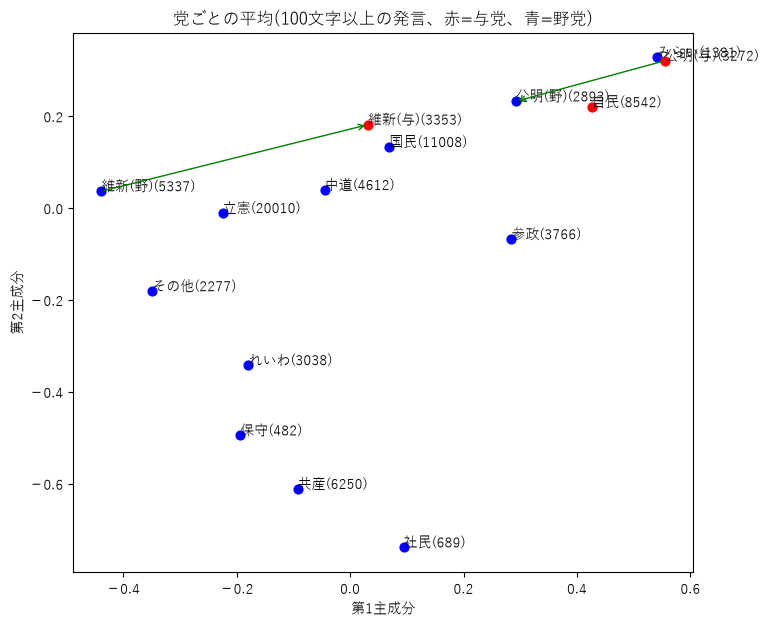

In [6]:
df["n_char"] = df["text"].str.len()
keep = (df["n_char"] >= 100).to_numpy()
d2 = df[keep].reset_index(drop=True)
X2 = X[keep]
print("残った発言:", len(d2), "件")

pca2 = PCA(n_components=2)
Z2 = pca2.fit_transform(X2)
d2["pc1"], d2["pc2"] = Z2[:, 0], Z2[:, 1]
print("説明できるばらつきの割合:", pca2.explained_variance_ratio_.round(3))

print("\n第一成分との相関係数")
print("  与党かどうか:", round(np.corrcoef(d2["pc1"], d2["gov"])[0, 1], 3))
print("  文字数(対数):", round(np.corrcoef(d2["pc1"], np.log1p(d2["n_char"]))[0, 1], 3))
print("  日付        :", round(np.corrcoef(d2["pc1"], d2["date"].astype("int64"))[0, 1], 3))
print("\n第二主成分との相関係数")
print("  与党かどうか:", round(np.corrcoef(d2["pc2"], d2["gov"])[0, 1], 3))
print("  文字数(対数):", round(np.corrcoef(d2["pc2"], np.log1p(d2["n_char"]))[0, 1], 3))
print("  日付        :", round(np.corrcoef(d2["pc2"], d2["date"].astype("int64"))[0, 1], 3))

g2 = d2.groupby("label").agg(
    pc1=("pc1", "mean"), pc2=("pc2", "mean"),
    n=("pc1", "size"), gov=("gov", "mean")
)
fig, ax = plt.subplots(figsize=(8, 7))
for lab, r in g2.iterrows():
    color = "red" if r["gov"] > 0.5 else "blue"
    ax.scatter(r["pc1"], r["pc2"], color=color, s=40)
    ax.annotate(f"{lab}({int(r['n'])})", (r["pc1"], r["pc2"]), fontsize=10)
for p, before, after in [("公明", "(与)", "(野)"), ("維新", "(野)", "(与)")]:
    a, b = g2.loc[p + before], g2.loc[p + after]
    ax.annotate("", xy=(b["pc1"], b["pc2"]), xytext=(a["pc1"], a["pc2"]), 
                arrowprops=dict(arrowstyle="->", color="green"))
ax.set_xlabel("第1主成分"); ax.set_ylabel("第2主成分")
ax.set_title("党ごとの平均(100文字以上の発言、赤=与党、青=野党)")
Path("../outputs").mkdir(exist_ok=True)
plt.savefig("../outputs/pca_parties_min100.png", dpi=150, bbox_inches="tight")
plt.show()

**結果**
- 残った発言は 76,910件。第1主成分は全体の 13.4%、第2主成分は 7.4%
- 第1主成分との相関: 与党かどうか 0.19、長さ −0.11、日付 0.13(どれも弱い)
- 図では、維新が野党(左)から与党(右)へ、公明が与党(右)から野党(左)へ動いており、「右 = 与党寄り」に見える

ただし、これが**立場の変化なのか、話し方の変化なのか**は、この図だけでは分からない。

次に見るもの: ① 党の違いで、主成分のばらつきの何割を説明できるか ② 公明の離脱(2025-10-10)の前と後で、党ごとの第1主成分の平均がどれだけ動いたか

In [7]:
# (1) 党の違いで、主成分のばらつきの何割を説明できるか
for c in ["pc1", "pc2"]:
    party_mean = d2.groupby("label")[c].transform("mean")
    total = ((d2[c] - d2[c].mean()) ** 2).sum()
    between = ((party_mean - d2[c].mean()) ** 2).sum()
    print(c, "党で説明できる割合:", round(between / total, 3))

# (2) 2025-10-10 の前と後で、党ごとの第1主成分の平均がどれだけ動いたか
d2["after"] = d2["date"] >= "2025-10-10"
t = d2.groupby(["party", "after"])["pc1"].mean().unstack()
t.columns = ["前", "後"]
t["変化"] = t["後"] - t["前"]
t["件数(後)"] = d2[d2["after"]].groupby("party").size()
print(t.round(3).sort_values("変化"))

pc1 党で説明できる割合: 0.083
pc2 党で説明できる割合: 0.115
           前      後     変化  件数(後)
party                            
参政     0.588  0.271 -0.317   3609
公明     0.555  0.292 -0.263   2893
共産    -0.084 -0.105 -0.021   2546
立憲    -0.259 -0.154  0.105   6565
国民    -0.035  0.138  0.173   6616
れいわ   -0.247 -0.042  0.205   1002
その他   -0.440 -0.189  0.251    827
社民    -0.051  0.228  0.278    359
保守    -0.421 -0.085  0.336    326
自民     0.230  0.638  0.407   4102
維新    -0.438  0.032  0.470   3353
みらい      NaN  0.541    NaN   1381
中道       NaN -0.045    NaN   4612


**結果**
- ① **党の違いで説明できるのは、第1主成分のばらつきの 8.3%、第2主成分の 11.5% だけ**。ほとんどのばらつきは、同じ党の中の発言どうしの違い
- ② 前後の変化: 維新 +0.47・自民 +0.41 が右へ、参政 −0.32・公明 −0.26 が左へ。ただし、ほかの多くの党(保守 +0.34・社民 +0.28 など)も右へ動いており、全体の動きと党の動きが混ざっている

衆議院と参議院では、話す場や議員の顔ぶれが違うので、院ごとに分けて見る。

In [8]:
for house in ["衆議院", "参議院"]:
    s = d2[d2["nameOfHouse"] == house]
    m = s.groupby(["party", "after"])["pc1"].mean().unstack()
    n = s.groupby(["party", "after"]).size().unstack()
    t = pd.DataFrame({
        "前": m[False], "後": m[True], "変化": m[True] - m[False], 
        "件数(前)": n[False], "件数(後)": n[True], 
    })
    print(house)
    print(t.round(3).sort_values("変化"))
    print()


衆議院
           前      後     変化   件数(前)   件数(後)
party                                     
参政     0.692  0.400 -0.292   143.0  1643.0
公明     0.660  0.463 -0.197  1401.0   381.0
立憲    -0.244 -0.293 -0.049  8903.0  1845.0
国民     0.139  0.115 -0.024  2462.0  3525.0
共産     0.140  0.219  0.079  1709.0   948.0
その他   -0.707 -0.626  0.081   548.0   331.0
れいわ   -0.285 -0.190  0.095  1331.0   260.0
自民     0.349  0.767  0.418  2580.0  2211.0
維新    -0.314  0.177  0.490  3080.0  1503.0
みらい      NaN  0.558    NaN     NaN  1182.0
中道       NaN -0.050    NaN     NaN  4593.0
保守    -0.421    NaN    NaN   156.0     NaN

参議院
           前      後     変化   件数(前)   件数(後)
party                                     
公明     0.477  0.266 -0.211  1871.0  2506.0
共産    -0.276 -0.297 -0.021  1995.0  1598.0
立憲    -0.284 -0.100  0.184  4518.0  4705.0
れいわ   -0.175  0.010  0.185   705.0   742.0
社民    -0.051  0.228  0.278   330.0   359.0
その他   -0.278  0.103  0.381   902.0   496.0
国民    -0.253  0.167  0.420  1918.0  3078.0
自民

**結果**: 衆議院では、自民 +0.42・維新 +0.49 が右へ、参政 −0.29・公明 −0.20 が左へ。参議院でも、自民 +0.42・維新 +0.52 が右へ、公明 −0.21 が左へ。ただし参議院では国民 +0.42・参政 +0.64 も右へ動いており(参政は前の件数が14件だけで当てにならない)、党の動きと全体の動きが分けにくい。

衆議院だけで、月ごとの党の位置を描く。**図の読み方**: 縦軸 = その月の全体平均との差(全体の動きを引いて、党どうしの位置だけを見る)。点線 = 公明の離脱(2025-10-10)、点々の線 = 衆院選(2026-02-08)。件数が30件未満の月は描いていない。

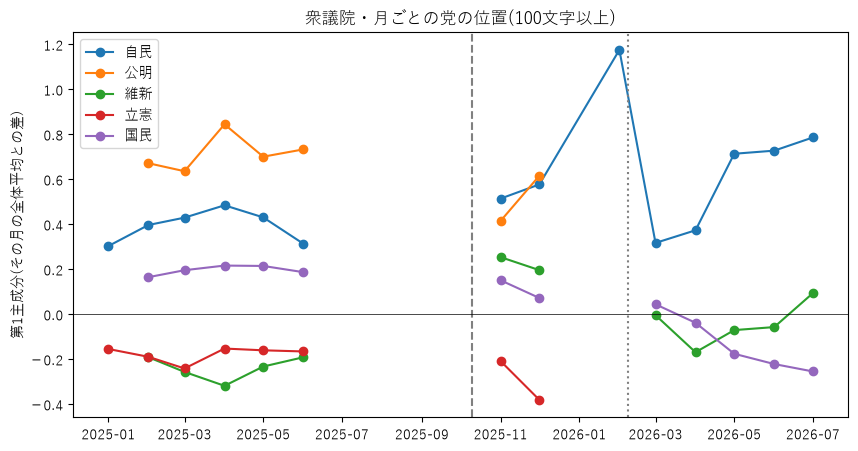

In [9]:
d2h = d2[d2["nameOfHouse"] == "衆議院"].copy()   # 衆議院だけ。d2 はそのまま残る
d2h["month"] = d2h["date"].dt.to_period("M")

monthly_all = d2h.groupby("month")["pc1"].mean()               # その月の全体平均
pm = d2h.groupby(["month", "party"])["pc1"].mean().unstack()   # 月×党の平均
cnt = d2h.groupby(["month", "party"]).size().unstack()         # 月×党の件数
rel = pm.sub(monthly_all, axis=0).where(cnt >= 30)             # 全体平均との差。30件未満は空にする

fig, ax = plt.subplots(figsize=(10, 5))
for p in ["自民", "公明", "維新", "立憲", "国民"]:
    ax.plot(rel.index.to_timestamp(), rel[p], marker="o", label=p)
ax.axvline(pd.Timestamp("2025-10-10"), color="gray", linestyle="--")   # 公明の離脱
ax.axvline(pd.Timestamp("2026-02-08"), color="gray", linestyle=":")    # 衆院選
ax.axhline(0, color="black", linewidth=0.5)
ax.set_ylabel("第1主成分(その月の全体平均との差)")
ax.set_title("衆議院・月ごとの党の位置(100文字以上)")
ax.legend()
plt.savefig("../outputs/pc1_monthly_relative_shu.png", dpi=150, bbox_inches="tight")
plt.show()

**結果**: 再編の前は、公明と自民が上(右寄り)、立憲と維新が下。再編の後、維新は少し上がり、公明は自民に近づいた後、中道への合流で消える。自民は衆院選の後に大きく上がった(ただし 2026-02 の点は 37件だけで、ばらつきが大きい)。

月ごとの件数と、自民との差を表で確かめる。

In [10]:
parties = ["自民", "公明", "維新", "立憲", "国民", "中道"]
print(cnt[parties].fillna(0).astype(int))   # 月ごとの件数(信頼できる月かどうか)

gap = pm[parties].sub(pm["自民"], axis=0).where(cnt[parties] >= 30)   # 自民との差
print(gap.drop(columns="自民").round(2))

party     自民   公明    維新    立憲   国民    中道
month                                   
2025-01   45    5    15   123   13     0
2025-02  859  337   559  1953  397     0
2025-03  493  237   504  1373  413     0
2025-04  552  411  1001  2755  791     0
2025-05  405  272   642  1822  544     0
2025-06  213  132   349   827  293     0
2025-08    8    4     6    29    7     0
2025-09    5    3     4    21    4     0
2025-10    0    0     0     0    0     0
2025-11  251  241   167  1246  328     0
2025-12  163  140   119   599  175     0
2026-02   37    0     1     0    2   110
2026-03  259    0   203     0  631   905
2026-04  467    0   348     0  903  1361
2026-05  357    0   278     0  782  1187
2026-06  553    0   279     0  530   791
2026-07  124    0   108     0  174   239
party      公明    維新    立憲    国民    中道
month                                
2025-01   NaN   NaN -0.46   NaN   NaN
2025-02  0.27 -0.59 -0.59 -0.23   NaN
2025-03  0.21 -0.69 -0.67 -0.23   NaN
2025-04  0.36 -0.80 -0.64 -0.27

**結果**
- 2025-07(参院選)と 2026-01 は行が無く、2025-08〜10 も国会がほとんど開かれず、件数が少ない(0〜数十件)
- 自民との差で見ると、維新は再編前 −0.51〜−0.80 → 再編後 −0.26〜−0.78 で、2025-11 は近づいたが、2026-05 以降は再編前と同じくらい離れている → **はっきり近づいたとは言えない**
- 中道は −0.54〜−1.62

## 3. 第1主成分は何を測っているか

両端の発言を読む。衆議院の自民と立憲について、第1主成分が低い5件と高い5件。

In [11]:
pd.set_option("display.max_colwidth", 300)

def show_ends(data, party, k=5):
    s = data[data["party"] == party].sort_values("pc1")
    cols = ["date", "nameOfMeeting", "pc1", "text"]
    print(f"===== {party}:pc1 が低い {k} 件 =====")
    for _, r in s.head(k)[cols].iterrows():
        print(r["date"].date(), r["nameOfMeeting"], round(r["pc1"], 2))
        print(r["text"][:250], "\n")
    print(f"===== {party}:pc1 が高い {k} 件 =====")
    for _, r in s.tail(k)[cols].iterrows():
        print(r["date"].date(), r["nameOfMeeting"], round(r["pc1"], 2))
        print(r["text"][:250], "\n")

show_ends(d2h, "自民")
show_ends(d2h, "立憲")


===== 自民:pc1 が低い 5 件 =====
2025-02-27 予算委員会第五分科会 -1.99
やはり施設の中に、介護を分かっている人が専門家にならないと、ほかの分野もみんなそうなんだけれども、ベンダーに丸投げしちゃうから、大体使えないものを作って、使わなくなっちゃうという悪循環ですからね。是非そこを検討してもらいたいというふうに思います。 次に、延命治療についてであります。 これはちょっと私の地元の例を申し上げますけれども、支援者の方がおられて、そのお母さん、百六歳、デイサービスに行っていて、救急車で運ばれた、そうしたら脳溢血だったということでありました。意識がなかったということでありま 

2025-02-27 予算委員会第五分科会 -1.93
喫煙でもあれだけやったんですからね、農水省がやっているところ。だから、省庁を乗り越えてやれるというのは絶対できると思いますので、これはやはり早急な対応が必要だと思います。かなりの数の方が多分苦しんでいるというところでありまして、これは病気ですから、これは病なので、これに対してやはりしっかり対応していかなきゃいけない。それは、私は厚生労働省に是非先頭に立っていただきたいというふうに思っているところでありまして、そのためにはやはり資金が必要ですから、その資金の調達の在り方というのは是非検討いただきた 

2025-04-02 経済産業委員会 -1.88
なるほど、そういうふうな違いがあったんですね。では、新しいものを作ろうとするときに、本当に早く対応して新しいものを作っていくというのは、逆にラピダスなんかの方がいいんじゃないかなんという期待もできるわけだと思います。 本当に、今いろいろ私も一番初めに申し上げましたけれども、今後、世界の産業技術がとてつもなく進んでいって今と全然違う世の中になっていくと思うんですが、そのときにこんな世の中になるんじゃないかみたいな私の想像も申し上げたところでございますけれども、私が今物すごく注目しておりますのがグロ 

2025-05-14 内閣委員会 -1.82
そういったインセンティブを、まさに、先ほどちょっと言ったように、戻ってきたときのポジションを用意するだとか、あと、私、もう一点大事なのが、これが今日のメインのテーマとして考えているんですけれども、宿舎の問題です。 引っ越

**結果**
- 低い側: 「〜なんだけれども」「〜ちゃう」「〜ですよね」「ああ、そうなんですね」のような**くだけた話し方**の質問(自民も立憲も)
- 高い側: 「ただいま議題となりました法律案につきまして、提案の趣旨を御説明申し上げます」のような、**本会議や委員会での改まった説明**(自民は法律案の趣旨説明、立憲は修正案の趣旨説明)

→ 第1主成分は、党の立場ではなく、**話し方のかたさ**を表しているのではないか。

**気づいたこと**: 自民の高い側に、委員長報告(「〜における審査の経過及び結果を**御報告します**」)が1件残っていた。前処理の決まりは「御報告申し上げ / いたし」なので、「御報告します」という言い方は漏れる。議院運営委員会の「動議を提出いたします」(「緊急動議」ではない)も残っている。どちらも数は少ないが、前処理の決まりの漏れとして記録しておく。

次に、古い版の手続きの言い回し(附帯決議案の朗読など)が残っていないかを確かめる。

In [12]:
PROC = r"緊急動議|付帯決議案|案文の朗読|趣旨の説明に代え"
m = d2["text"].str.contains(PROC)
print("手続きの発言:", m.sum(), "件")
print(d2[m].groupby("party").size().sort_values(ascending=False))

手続きの発言: 1 件
party
国民    1
dtype: int64


**結果**: 1件(国民)だけ。100字以上の 76,910件のうちの1件なので、結果にはほぼ影響しない。

くだけた言い回し(「でしょう」「じゃない」「ちゃう」「よね」「んです」「けど」「ちょっと」など)の多さを、1000字あたりの回数(くだけ度)で数え、第1主成分との関係を見る。

In [13]:
CASUAL = r"でしょう|じゃない|ちゃう|ちゃっ|よね|だって|んです|んだ|けど|みたいな|ちょっと"
d2["casual"] = d2["text"].str.count(CASUAL) / d2["n_char"] * 1000   # 1000文字あたりの回数

print("第1主成分との相関:", round(np.corrcoef(d2["pc1"], d2["casual"])[0, 1], 3))

# 衆議院の維新・国民・自民で、再編の前後に話し方が変わったか
h = d2[d2["nameOfHouse"] == "衆議院"]
print(h[h["party"].isin(["維新", "国民", "自民"])]
      .groupby(["party", "after"])["casual"].mean().unstack().round(2))

第1主成分との相関: -0.621
after  False  True 
party              
国民      4.54   5.18
維新      7.34   4.73
自民      3.17   2.10


**結果**
- **くだけ度と第1主成分の相関は −0.62**(強い関係。くだけているほど左)
- 衆議院では、維新(7.34 → 4.73)と自民(3.17 → 2.10)が、再編の後にくだけた言い回しが減った。与党になり、答える側・改まった場が増えた可能性がある。国民は少し増えた(4.54 → 5.18)

次に、くだけ度と長さで説明できる分を第1主成分から引き(回帰の残り = `pc1_adj`)、残りで再編の前後を比べる。

In [14]:
from sklearn.linear_model import LinearRegression

Z = np.column_stack([d2["casual"], np.log1p(d2["n_char"])])   # 説明に使う2つ:くだけ度、長さ
lr = LinearRegression().fit(Z, d2["pc1"])
d2["pc1_adj"] = d2["pc1"] - lr.predict(Z)                      # 話し方と長さで説明できる分を引いた残り
print("話し方と長さで説明できる割合:", round(lr.score(Z, d2["pc1"]), 3))

h = d2[d2["nameOfHouse"] == "衆議院"]
t = (h[h["party"].isin(["維新", "国民", "自民"])]
     .groupby(["party", "after"])[["pc1", "pc1_adj"]].mean().unstack().round(2))
print(t)

話し方と長さで説明できる割合: 0.432
        pc1       pc1_adj      
after False True    False True 
party                          
国民     0.14  0.11   -0.02  0.03
維新    -0.31  0.18   -0.22  0.06
自民     0.35  0.77    0.10  0.41


**結果**
- **話し方(くだけ度)と長さだけで、第1主成分のばらつきの 43% を説明できた**(党の違いで説明できるのは 8%)
- 話し方と長さの分を引くと、衆議院の維新の前後の動きは +0.49 → +0.28 に小さくなった。自民の動き(+0.31)は残るが、これが立場の変化か、与党としての話す場の変化かは区別できない

**→ 第1主成分は、主に「話し方のかたさ」を表している。党の立場を測る物差しとしては使えない。**

---

## 4. (付録)前処理の点検

以下は、主成分を調べる途中で見つかった前処理の問題の点検。ここで分かったことは、`data/external/speaker_party_override.csv`・`speaker_exclude.csv` と、`scripts/02_preprocess.py` の手続きの発言を除く決まりに反映した。

まず、議員以外(公述人・参考人など)がよく使う言い回し(「御質問ありがとうございます」「参考人として」など)を含む発言を探す。

In [15]:
import pandas as pd

q3 = pd.read_parquet("../data/processed/speeches.parquet",
                     columns=["speechID", "date", "nameOfMeeting", "speaker",
                              "speakerGroup", "party", "text", "speechURL"])

# (a) 怪しかった 2025-02-14 予算委員会の「御質問ありがとうございます」
s = q3[(q3["date"] == "2025-02-14") & (q3["nameOfMeeting"] == "予算委員会")
       & q3["text"].str.contains("質問ありがとうございます", na=False)]
print(s[["speaker", "speakerGroup", "party", "speechURL"]].to_string())

# (b) 議員以外がよく使う言い回しを含む発言が、全体で何件あるか
GUEST = r"御質問ありがとうございます|質問ありがとうございます|公述人として|参考人として"
g = q3[q3["text"].str.contains(GUEST, na=False)]
print("\n言い回しを含む発言:", len(g), "件")
print(g.groupby("party").size().sort_values(ascending=False))
print(g.groupby("speaker").size().sort_values(ascending=False).head(15))

Empty DataFrame
Columns: [speaker, speakerGroup, party, speechURL]
Index: []

言い回しを含む発言: 253 件
party
立憲     84
国民     56
自民     29
維新     20
共産     19
公明     15
れいわ    13
中道      6
参政      5
その他     4
みらい     1
保守      1
dtype: int64
speaker
臼木秀剛     14
杉尾秀哉     11
山井和則      7
浜口誠       6
辰巳孝太郎     6
秋野公造      6
橋本幹彦      5
池下卓       5
重徳和彦      5
泉房穂       5
岡本充功      4
打越さく良     4
円より子      4
奥村祥大      4
石垣のりこ     4
dtype: int64


**結果**
- (a) 最初に疑った 2025-02-14 の予算委員会(公聴会)の発言は、今のデータには無い(公述人の知事を除く表で除けている)
- (b) 言い回しを含む発言は 253件。どの党にも少しずつあり、発言者を見ると議員の名前が並ぶ → 議員以外の発言が大量に紛れているわけではなさそう(議員自身が「参考人として来ていただいた〜」のように使う場面もある)

党ごとの発言の期間と、「福島」という名前の議員の会派・党を確かめる。

In [16]:
q2 = q3[["date", "speaker", "speakerGroup", "party"]]
print(q2.groupby("party")["date"].agg(["min", "max", "size"]))

f = q2[q2["speaker"].str.contains("福島", na=False)]
print(f.groupby(["speaker", "speakerGroup", "party"])["date"].agg(["min", "max", "size"]))

             min        max   size
party                             
その他   2025-02-03 2026-07-23   2633
みらい   2025-11-25 2026-07-27   1465
れいわ   2025-01-23 2026-07-24   3637
中道    2026-02-18 2026-07-27   5248
保守    2025-02-25 2026-07-16    589
公明    2025-01-23 2026-07-24   6841
共産    2025-01-22 2026-07-27   7457
参政    2025-02-25 2026-07-27   4082
国民    2025-01-23 2026-07-27  12281
社民    2025-03-13 2026-07-16    866
立憲    2025-01-23 2026-07-24  23621
維新    2025-01-23 2026-07-27   9759
自民    2025-01-23 2026-07-27   9536
                                  min        max  size
speaker speakerGroup party                            
福島みずほ   社会民主党        社民    2026-03-31 2026-07-16   224
        立憲民主・社民・無所属  社民    2025-03-13 2026-01-23   186
福島伸享    有志の会         その他   2025-02-07 2025-12-15   228


**結果**: 党ごとの期間は、それぞれの党の活動期間と合っている(中道は 2026-02-18 から、みらいは 2025-11-25 から)。福島みずほ議員(社民党首)は、2026-01 までは会派「立憲民主・社民・無所属」、その後は「社会民主党」。会派の名前で党を決めると、2026-01 までは「立憲」になってしまう(この出力は、党を手で指定する表を入れた後に実行したので、どちらの期間も「社民」と表示されている)。

会派と、割り当てた党の対応を、人数・件数と一緒に確かめる。合同会派(「立憲民主・社民・無所属」など)では、会派の名前だけでは党が決まらない議員がいる。

In [17]:
# (1) 会派ごとに、割り当てた党と、発言者の人数・件数
grp = q2.groupby(["speakerGroup", "party"]).agg(人数=("speaker", "nunique"), 件数=("speaker", "size"))
print(grp.sort_values("件数", ascending=False).to_string())

# (2) 合同会派の発言者の一覧
for gname in ["立憲民主・社民・無所属"]:
    print("\n=====", gname)
    print(q2[q2["speakerGroup"] == gname].groupby("speaker").size().sort_values(ascending=False).to_string())

# (3) みらいの安野貴博議員の発言が、どの会派に入っているか
print(q2[q2["speaker"].str.contains("安野", na=False)]
      .groupby(["speakerGroup", "party"])["date"].agg(["min", "max", "size"]))

                     人数     件数
speakerGroup party            
立憲民主党・無所属    立憲     140  12677
日本維新の会       維新      70   9759
日本共産党        共産      21   7457
自由民主党・無所属の会  自民     319   7211
公明党          公明      52   6841
国民民主党・無所属クラブ 国民      36   6627
立憲民主・社民・無所属  立憲      48   6262
国民民主党・新緑風会   国民      25   5654
中道改革連合・無所属   中道      46   5248
立憲民主・無所属     立憲      38   4682
参政党          参政      32   4082
れいわ新選組       れいわ     16   3637
自由民主党        自民      92   2325
チームみらい       みらい     11   1247
各派に属しない議員    その他     10    934
有志の会         その他      4    745
日本保守党        保守       5    589
沖縄の風         その他      3    531
立憲民主・社民・無所属  社民       3    478
社会民主党        社民       2    388
無所属          その他      6    248
チームみらい・無所属の会 みらい      2    204
ＮＨＫから国民を守る党  その他      2    117
減税保守こども      その他      2     20
改革の会         その他      2     20
ＮＨＫ党         その他      1     18
各派に属しない議員    みらい      1     14

===== 立憲民主・社民・無所属
speaker
村田享子      354
石橋通宏      274
大椿ゆうこ     266
古賀之士      261
塩村あやか     253
川田龍平

**結果**: 「立憲民主・社民・無所属」には、立憲の議員 48人と社民の議員 3人(478件)が入っている。みらいの安野貴博議員(党首)は、2025年は「各派に属しない議員」だった(14件。今は表で「みらい」にしてある)。

→ **会派だけでは党が決まらない議員**を、党を手で指定する表にする。公述人として発言した知事(元参院議員で、API が会派を付けていた)は除く表にする。

In [18]:
EXT = Path("../data/external")

override = pd.DataFrame({
    "speaker": ["福島みずほ", "大椿ゆうこ", "ラサール石井", "安野貴博"],
    "party":   ["社民",       "社民",       "社民",         "みらい"],
    "note":    ["社民党首。2026-01まで会派「立憲民主・社民・無所属」",
                "社民副党首。2025-07任期満了まで同会派",
                "社民。2025-07初当選、2026-01まで同会派",
                "チームみらい党首。2025年は「各派に属しない議員」"],
})
override.to_csv(EXT / "speaker_party_override.csv", index=False, encoding="utf-8")

exclude = pd.DataFrame({
    "speaker": ["山本一太"],
    "reason":  ["公述人(群馬県知事、2025-02-14 衆院予算委員会公聴会)。API が元参院議員の会派を付けていた"],
})
exclude.to_csv(EXT / "speaker_exclude.csv", index=False, encoding="utf-8")

print(pd.read_csv(EXT / "speaker_party_override.csv"))
print(pd.read_csv(EXT / "speaker_exclude.csv"))

  speaker party                           note
0   福島みずほ    社民  社民党首。2026-01まで会派「立憲民主・社民・無所属」
1   大椿ゆうこ    社民         社民副党首。2025-07任期満了まで同会派
2  ラサール石井    社民     社民。2025-07初当選、2026-01まで同会派
3    安野貴博   みらい     チームみらい党首。2025年は「各派に属しない議員」
  speaker                                                reason
0    山本一太  公述人(群馬県知事、2025-02-14 衆院予算委員会公聴会)。API が元参院議員の会派を付けていた


**結果**: 党を手で指定する4人(福島みずほ・大椿ゆうこ・ラサール石井 → 社民、安野貴博 → みらい)と、除く1人(山本一太・群馬県知事)を保存した。

次の5つのセルは、手続きの発言(附帯決議案の朗読など、議員の考えではない発言)を除く決まりの点検。

**いきさつ**: 最初は「附帯決議案」「緊急動議」などの言葉を**含むだけで**消す広い決まりにしていた。読み直すと、「附帯決議に反対の立場から討論を行います」のような、議員の考えを述べたふつうの発言まで消していた → 手続きの決まり文句(「案文を朗読」「附帯決議案を提出」など)にしぼった(`scripts/02_preprocess.py` の `PROC`)。ここでは、しぼった後の決まりで**消えた発言**と**残した発言**が正しいかを確かめる。

まず、埋め込みを作ったとき(04)にはあって、今の前処理の結果には無い発言(= その後の前処理で消えた発言)を集める。

In [19]:
import json

# 元の会議録をすべて読み込む
rows = []
for p in sorted(Path("../data/raw/kokkai").glob("speech_*.json")):
    rows += json.loads(p.read_text(encoding="utf-8")).get("speechRecord", [])
raw = pd.DataFrame(rows)
print("元の会議録:", len(raw), "件")

# 埋め込みを作ったとき(04)の発言にはあって、今の前処理の結果にはない発言 = その後の前処理で消えた発言
old_ids = pd.read_csv("../data/embeddings/emb/speech_ids.csv")["speechID"]
new_ids = pd.read_parquet("../data/processed/speeches.parquet", columns=["speechID"])["speechID"]
dropped = raw[raw["speechID"].isin(old_ids) & ~raw["speechID"].isin(new_ids)]
members = dropped[dropped["speaker"] != "山本一太"]     # 公述人の知事を除いた、議員の発言
print("消えた発言:", len(dropped), "件")

# そのうち、前の広い手続きのパターンに当たる発言
BROAD = r"緊急動議|附帯決議案|案文の朗読|趣旨の説明に代え"
proc = dropped[dropped["speech"].str.contains(BROAD, na=False)]
print("\n前の広いパターンに当たる発言:", len(proc), "件")
print("文字数の分布:")
print(proc["speech"].str.len().describe().round(0))
for t in proc.sample(10, random_state=0)["speech"]:
    print(t[:150], "\n")

元の会議録: 194567 件
消えた発言: 282 件

前の広いパターンに当たる発言: 254 件
文字数の分布:
count     254.0
mean     1419.0
std      1042.0
min        85.0
25%       730.0
50%      1196.0
75%      1999.0
max      6838.0
Name: speech, dtype: float64
○中川（宏）委員　ただいま議題となりました附帯決議案につきまして、提出者を代表して、その趣旨を御説明申し上げます。
　案文の朗読により趣旨の説明に代えさせていただきます。
　　　　放送法第七十条第二項の規定に基づき、承認を求めるの件に対する附帯決議（案）
　　政府及び日本放送協会は、次の各項の 

○津村委員　ただいま議題となりました附帯決議案につきまして、提出者を代表いたしまして、その趣旨を御説明申し上げます。
　趣旨の説明は、案文を朗読して代えさせていただきたいと存じます。
　　　　航空法等の一部を改正する法律案に対する附帯決議（案）
　　政府は、本法の施行に当たっては、次の諸点に留 

○神谷委員　ただいま議題となりました附帯決議案につきまして、提出者を代表して、その趣旨を御説明申し上げます。
　案文を朗読して趣旨の説明に代えさせていただきます。
　　　　家畜伝染病予防法の一部を改正する法律案に対する附帯決議（案）
　　令和二年に行われた家畜伝染病予防法の総合的な見直しの後に 

○柴愼一君　私は、ただいま可決されました株式会社日本政策投資銀行法の一部を改正する法律案に対し、自由民主党、立憲民主・社民・無所属、公明党、日本維新の会及び国民民主党・新緑風会の各派並びに各派に属しない議員梅村みずほ君、大野泰正君及び神谷宗幣君の共同提案による附帯決議案を提出いたします。
　案文を 

○小寺裕雄君　議事日程追加の緊急動議を提出いたします。
　内閣提出、地方税法等の一部を改正する法律案、地方交付税法等の一部を改正する法律案、放送法第七十条第二項の規定に基づき、承認を求めるの件、右三件を一括議題とし、委員長の報告を求め、その審議を進められることを望みます。 

○後藤（祐）委員　ただいま議題となりました附帯決議案につきまして、提出者を代表して、

**結果**: 消えた発言は 282件。そのうち 254件が前の広いパターンに当たり、文字数の中央値は 1,196字と長い。読むと、附帯決議案の提出と案文の朗読、緊急動議の提出など、**手続きの発言**ばかりだった。

広いパターンには当たるが、手続きの決まり文句(「緊急動議を提出」「趣旨の説明に代え」)には当たらない発言を読む。

In [20]:
BROAD  = r"緊急動議|附帯決議案|案文の朗読|趣旨の説明に代え"   # 今のスクリプトのパターン
STRICT = r"緊急動議を提出|趣旨の説明に代え"                  # 手続きの決まり文句だけ

members = dropped[dropped["speaker"] != "山本一太"]
only_broad = members[members["speech"].str.contains(BROAD, na=False)
                     & ~members["speech"].str.contains(STRICT, na=False)]
print("広いパターンだけに当たった発言:", len(only_broad), "件")
for t in only_broad.sample(min(10, len(only_broad)), random_state=0)["speech"]:
    print(t[:200], "\n")

広いパターンだけに当たった発言: 136 件
○山崎（誠）委員　ただいま議題となりました附帯決議案につきまして、提出者を代表し、その趣旨を御説明申し上げます。
　本法律案に関わる委員会審査においては、選定事業者としてラピダスを想定した質疑が行われました。これを踏まえ、政府に対し、以下のとおり求めるものであります。
　まず、案文を朗読いたします。
　　　　情報処理の促進に関する法律及び特別会計に関する法律の一部を改正する法律案に対する附帯 

○矢崎委員　ただいま議題となりました附帯決議案につきまして、提出者を代表いたしまして、案文を朗読し、趣旨の説明といたします。
　　　　関税定率法等の一部を改正する法律案に対する附帯決議（案）
　　政府は、次の事項について、十分配慮すべきである。
　一　関税率の設定に当たっては、我が国の貿易をめぐる諸情勢を踏まえ、国民経済的な視点から国内産業、特に農林水産業及び中小企業の利益を十分に配慮しつつ 

○岡田（悟）委員　ただいま議題となりました附帯決議案につきまして、提出者を代表いたしまして、案文を朗読し、趣旨の説明といたします。
　　　　保険業法の一部を改正する法律案に対する附帯決議（案）
　　政府は、次の事項について、十分配慮すべきである。
　一　今般の保険金不正請求事案及び保険料調整行為事案の再発防止策が、本法による措置及び下位法令への委任のほか、顧客本位ではない比較推奨販売の禁止、 

○梅村みずほ君　私は、ただいま可決されました廃棄物の処理及び清掃に関する法律等の一部を改正する法律案に対し、自由民主党・無所属の会、立憲民主・無所属、国民民主党・新緑風会、公明党、日本維新の会、参政党、沖縄の風及びチームみらい・無所属の会の各派並びに各派に属しない議員望月良男君の共同提案による附帯決議案を提出いたします。
　案文を朗読いたします。
　　　　廃棄物の処理及び清掃に関する法律等の一 

○田島麻衣子君　私は、ただいま可決されました民事裁判情報の活用の促進に関する法律案に対し、自由民主党、立憲民主・社民・無所属、公明党、日本維新の会及び国民民主党・新緑風会の各派並びに各派に属しない議員鈴木宗男君の共同提案による附帯決議案を提出いたします。
　案文を朗読いたします。
　　　　民事裁判情報の活用の促進に関する法律案に対する附帯決議（案）


**結果**: 136件。読むと、「案文を朗読いたします」「案文を朗読し、趣旨の説明といたします」のような、別の言い方の手続きの発言だった → 決まり文句を足して、もう一度数える。

In [21]:
PROC2 = r"緊急動議を提出|趣旨の説明に代え|趣旨の説明といたします|案文を朗読|案文の朗読|附帯決議案を提出"

rest = members[members["speech"].str.contains(BROAD, na=False)
               & ~members["speech"].str.contains(PROC2, na=False)]
print("手続きの言い回しを含まない発言:", len(rest), "件")
for t in rest["speech"]:
    print(t[:200], "\n")

手続きの言い回しを含まない発言: 1 件
○長友（よ）委員　ただいま議題となりました附帯決議案につきまして、提出者を代表して、その趣旨を御説明申し上げます。
　趣旨の説明は、案文朗読をもって代えたいと思います。どうぞよろしくお願いいたします。
　　　　道路法等の一部を改正する法律案に対する附帯決議（案）
　　政府は、本法の施行に当たっては、次の諸点に留意し、その運用について遺漏なきを期すべきである。
　一　令和六年能登半島地震によ 



**結果**: 足した決まり文句にも当たらないのは 1件だけ。「案文**朗読**をもって代えたい」という言い方で、これも手続き → 決まりに「案文朗読」を足した(`PROC` に入っている)。

次に、前の広いパターンには当たらないのに、今の決まりで消えた発言を読む(消しすぎていないかの確認)。

In [22]:
# 前の広いパターンには当たらないのに、今の決まりで消えた発言
new_only = members[~members["speech"].str.contains(BROAD, na=False)]
print("新しく消えた発言:", len(new_only), "件\n")
for t in new_only["speech"]:
    print(t[:200], "\n")

新しく消えた発言: 14 件

○野田国義君　私は、自由民主党、立憲民主・社民・無所属、公明党、日本維新の会及び国民民主党・新緑風会の各派共同提案による自立した安定的な財政運営を実現するための地方税財政制度の構築等に関する決議案を提出いたします。
　案文を朗読させていただきます。
　　　　自立した安定的な財政運営を実現するための地方税財政制度の構築等に関する決議（案）
　　地方公共団体が人口減少の下で疲弊する地域経済の現状 

○田名部匡代君　私は、自由民主党、立憲民主・社民・無所属、公明党、日本維新の会及び国民民主党・新緑風会の各派並びに各派に属しない議員寺田静さんの共同提案による新たな食料・農業・農村基本計画に基づく施策の推進に関する決議案を提出いたします。
　案文を朗読いたします。
　　　　新たな食料・農業・農村基本計画に基づく施策の推進に関する決議（案）
　　地球規模での気候変動や国際情勢の不安定化などによ 

○眞野委員　私は、提出者を代表いたしまして、本動議について御説明申し上げます。
　案文を朗読して説明に代えさせていただきます。
　　　　大学等における修学の支援に関する法律の一部を改正する法律案に対する附帯決議（案）
　　政府及び関係者は、本法の施行に当たっては、次の事項について特段の配慮をすべきである。
　一　高等教育の修学支援新制度は、学生等に対する経済的支援の面を持つ一方で、大学等に 

○川田龍平君　ただいま議題となりました自由民主党、立憲民主・社民・無所属、公明党、日本維新の会、国民民主党・新緑風会、日本共産党及び沖縄の風の各派並びに各派に属しない議員鈴木宗男君及び神谷宗幣君の共同提案に係る決議案につきまして、発議者を代表し、提案の趣旨を御説明申し上げます。
　案文を朗読いたします。
　　　　国際協同組合年に当たり協同組合の振興を図る決議案
　　国際連合は、二〇二三年十二 

○日野委員　私は、提出者を代表いたしまして、本動議について御説明申し上げます。
　案文を朗読して説明に代えさせていただきます。
　　　　公立の義務教育諸学校等の教育職員の給与等に関する特別措置法等の一部を改正する法律案に対する附帯決議（案）
　　政府及び関係者は、本法の施行に当たっては、次の事項について特段の配慮をすべきである。
　一　教育職員の時間外在校等時間を令和

**結果**: 14件で、どれも「〜に関する決議案を提出いたします。案文を朗読いたします」のような、**決議案の朗読**だった(附帯決議案ではないので、前の広いパターンには当たらなかった)→ 正しく消せている。

(消えた 282件のうち、広いパターンに当たらない 28件は、この決議案の 14件と、除く表に入れた知事(公述人)の発言 14件)

最後に、手続きの言い回しを含むのに残した発言を確かめる(1行目だけ表示)。

In [23]:
new_ids = pd.read_parquet("../data/processed/speeches.parquet", columns=["speechID"])["speechID"]
PROC = r"緊急動議を提出|趣旨の説明に代え|趣旨の説明といたします|案文を朗読|案文の朗読|案文朗読|附帯決議案を提出"
kept = raw[raw["speechID"].isin(new_ids)
           & raw["speech"].str.contains(PROC, na=False)]
print("手続きの言い回しを含むが残した発言:", len(kept), "件")
for t in kept["speech"]:
    print(t.split("\n")[0][:100])

手続きの言い回しを含むが残した発言: 4 件
○稲富修二君　立憲民主党・無所属の稲富修二です。
○井坂委員　立憲民主党・無所属の井坂信彦です。
○後藤（祐）委員　私は、会派を代表して、ただいま議題となりました令和八年度一般会計予算、令和八年度特別会計予算及び令和八年度政府関係機関予算につき撤回のうえ編成替えを求めるの動議に関して、その趣旨を御
○中野（洋）委員　私は、会派を代表して、ただいま議題となりました令和八年度一般会計補正予算（第１号）及び令和八年度特別会計補正予算（特第１号）につき撤回のうえ編成替えを求めるの動議に関して、その趣旨を


**結果**: 4件。うち2件は、会派を代表した予算の組み替え動議の趣旨説明で、議員の考えを述べた発言 → 残すのが正しい。ほかの2件(1行目が自己紹介のもの)は、1行目だけでは中身が分からないので、どの言い回しに当たったかは確かめていない。

## まとめ

- BERT の埋め込みの第1主成分は、党の立場よりも**話し方のかたさと発言の長さ**を強く表していた(話し方と長さで 43%、党の違いで 8%)
- 再編の前後で党の位置が動いたように見えても、話し方の変化(与党になって改まった場が増えた、など)と区別できない
- このため、**会議録 × BERT で党の立場を測るのはやめた**。種の文で「右 − 左」の向きを決める方法(`06_seed_axis_test.ipynb`)も試したが、立場を安定して取り出せなかった
- 立場の測定は、選挙公約を政策ごとに LLM で判定する方法を主にする(README の「どうやって測るか」)
- 途中で見つかった前処理の問題(短い発言、議員以外の発言、会派と党の対応、手続きの発言)は、前処理か分析の手順に反映した

**限界**
- 主成分分析は、ばらつきの大きい向きを見つける方法なので、立場の違いが小さな向きに隠れている可能性は残る
- くだけ度は、自分で選んだ言い回しの数で測った粗い指標
- 委員長報告の言い方の揺れ(「御報告します」)など、前処理の決まりで漏れている発言が少し残る